# ISM 6564 — Week 1: Text as Data & Tokenization

**Lecture notebook — Wednesday, August 26, 2026**

The deck argues; this notebook *measures*. Everything asserted in class today is
computed here from a real corpus, on your machine, with numbers you can change.

By the end you will have:

- measured why an open vocabulary makes word-level tokenization structurally
  unfixable — not merely inconvenient;
- implemented **BPE from scratch** and reproduced the Hugging Face trainer's
  vocabulary *exactly*, including its tie-breaking;
- watched **WordPiece emit `[UNK]`** on text that **byte-level BPE swallows whole**;
- trained BPE, WordPiece, Unigram and SentencePiece models on the same corpus;
- priced the same document in five languages and found a **5.6×** cost gap;
- and seen exactly why a language model cannot count the r's in *strawberry*.

**Sections mirror the deck's blocks**, so the instructor can jump straight to one:

| § | Block |
|---|---|
| 0 | Setup |
| 1 | Why text is hard |
| 2 | The unit problem |
| 3 | Subword tokenization — *the core of the week* |
| 4 | Living with a tokenizer |
| 5 | Tokens as money and as failure |
| 6 | Normalization, briefly |
| 7 | Where this goes next |

## 0. Setup

Two things before we start.

**The device block.** Nothing in Week 1 needs a GPU — tokenization is a string
operation. But every notebook in this course opens the same way, so the habit is
in place when it matters, and so the notebook is portable between your laptop, a
lab machine, and Colab without edits.

**Seeds.** The only stochastic step today is the synthetic-corpus sampler, but
seeding `random`, `numpy` and `torch` unconditionally is the cheap habit. If a
number in your run differs from a number in mine, that is a bug worth chasing,
not noise to shrug at.

In [1]:
import json
import logging
import os
import random
import re
import unicodedata
from collections import Counter
from pathlib import Path

# Quiet the Hugging Face Hub's "unauthenticated request" notice. We only download
# tokenizer files (a few hundred KB), so rate limits are not a concern here.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import torch

SEED = 6564
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("torch", torch.__version__, "| device:", device)

torch 2.11.0 | device: mps


### 0.1 A house style for the figures

Three figures in this notebook. They use a fixed categorical order (never a
cycled colour), one y-axis per chart, recessive gridlines, and a legend whenever
more than one series is on screen. Colour is the *last* decision, not the first.

In [2]:
# Fixed categorical slots — assigned in order, never cycled.
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
INK, MUTED = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})

### 0.2 Data

Three files, all in `data/`. Each loads **local first, URL second**, so this
notebook runs identically from a clone of the repo and from a bare Colab
runtime. `data/README.md` documents the source and licence of each.

| File | What it is |
|---|---|
| `moby_dick.txt` | Melville, *Moby-Dick* (1851), public domain — 1.2 MB of real English prose. Big enough for honest vocabulary statistics, small enough to train a tokenizer on in under a second. |
| `udhr_parallel.json` | The Universal Declaration of Human Rights in five languages. Same document, same meaning, five scripts — the only fair way to compare token costs across languages. |
| `support_tickets.jsonl` | 400 synthetic customer-support tickets for an online retailer. Order IDs, SKUs, tracking numbers, URLs, prices, emoji. This is what business text actually looks like when it hits a tokenizer. |

In [3]:
DATA = Path("data")
BASE = "https://raw.githubusercontent.com/prof-tcsmith/6564F26-DATA/main/week-01-text-tokenization/data"


def load_text(name: str) -> str:
    local = DATA / name
    if local.exists():
        return local.read_text(encoding="utf-8")
    import urllib.request
    with urllib.request.urlopen(f"{BASE}/{name}") as fh:
        return fh.read().decode("utf-8")


MOBY = load_text("moby_dick.txt")
UDHR = json.loads(load_text("udhr_parallel.json"))
TICKETS = [json.loads(line) for line in load_text("support_tickets.jsonl").splitlines() if line]

print(f"moby_dick.txt        {len(MOBY):>9,} characters")
print(f"udhr_parallel.json   {len(UDHR)} languages: {', '.join(UDHR)}")
print(f"support_tickets.jsonl {len(TICKETS):>8,} tickets, "
      f"{sum(len(t['text']) for t in TICKETS):,} characters")

moby_dick.txt        1,220,066 characters
udhr_parallel.json   5 languages: English, German, Spanish, Hindi, Chinese (Simplified)
support_tickets.jsonl      400 tickets, 58,064 characters


### 0.3 One paragraph, used everywhere

Every tokenizer in §2 and §3 gets the *same* input. It is deliberately nasty, and
every nasty thing in it is something you will actually meet in a support inbox:
an abbreviation with a period, clitics (`'s`, `n't`, `'ve`), a hyphenated
compound, a structured order ID, a URL with a query string, a clock time with
periods, an ISO date, a currency amount with both a comma and a decimal point,
an emoji, and a run of Japanese with no spaces in it at all.

In [4]:
PARA = (
    "Dr. Okafor's order (ORD-2026-448120) didn't arrive — the co-worker who signed "
    "for it can't find it. Tracking says https://track.example.com/1Z9847?u=2 was "
    "\"delivered\" at 3:45 p.m. on 2026-08-14. We've refunded $1,234.56 to the card "
    "ending 4417, but she's still upset 😤. 東京の配送センターに連絡しました。"
)
print(PARA)
print(f"\n{len(PARA)} Unicode characters, {len(PARA.split())} whitespace-separated chunks")

Dr. Okafor's order (ORD-2026-448120) didn't arrive — the co-worker who signed for it can't find it. Tracking says https://track.example.com/1Z9847?u=2 was "delivered" at 3:45 p.m. on 2026-08-14. We've refunded $1,234.56 to the card ending 4417, but she's still upset 😤. 東京の配送センターに連絡しました。

287 Unicode characters, 40 whitespace-separated chunks


---

## 1. Why text is hard

Framing, but framing with numbers. The claim from the deck is that text is not
"just another feature type": it is **discrete, unbounded, and heavy-tailed**. All
three are measurable, so let us measure them on 1.2 MB of English prose.

### 1.1 Zipf's law: a few words do almost all the work

Rank every distinct word by frequency and the *r*-th most common word occurs
roughly proportionally to $1/r$. On a log–log plot that is a straight line. The
consequence is the part that matters: an enormous share of your text is a
handful of word types, and an enormous share of your *vocabulary* is words you
will see once and never again.

In [5]:
words = re.findall(r"[a-z']+", MOBY.lower())
counts = Counter(words)

print(f"tokens (running words): {len(words):,}")
print(f"types  (distinct words): {len(counts):,}\n")
print(f"{'rank':>4}  {'word':<10} {'count':>7}")
for rank, (w, n) in enumerate(counts.most_common(10), start=1):
    print(f"{rank:>4}  {w:<10} {n:>7,}")

hapax = sum(1 for n in counts.values() if n == 1)
print(f"\nwords occurring exactly once: {hapax:,} "
      f"({100 * hapax / len(counts):.1f}% of the vocabulary)")

tokens (running words): 216,106
types  (distinct words): 17,500

rank  word         count
   1  the         14,425
   2  of           6,609
   3  and          6,428
   4  a            4,722
   5  to           4,625
   6  in           4,171
   7  that         2,989
   8  his          2,530
   9  it           2,419
  10  i            1,981

words occurring exactly once: 7,775 (44.4% of the vocabulary)


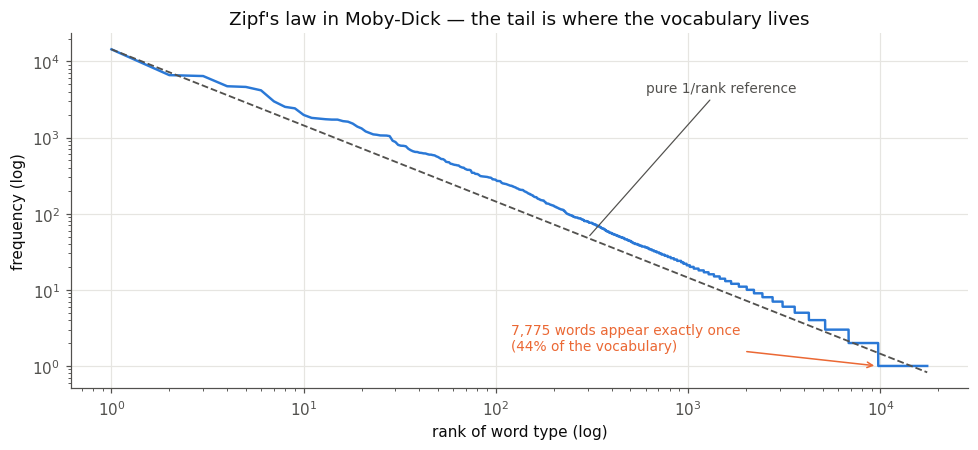

In [6]:
freqs = np.array([n for _, n in counts.most_common()])
ranks = np.arange(1, len(freqs) + 1)

fig, ax = plt.subplots()
ax.loglog(ranks, freqs, color=C1, lw=1.6)
ax.loglog(ranks, freqs[0] / ranks, color=MUTED, lw=1.2, ls="--")
ax.annotate("pure 1/rank reference", xy=(300, freqs[0] / 300), xytext=(600, 4000),
            color=MUTED, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.annotate(f"{hapax:,} words appear exactly once\n"
            f"({100 * hapax / len(counts):.0f}% of the vocabulary)",
            xy=(len(freqs) * 0.55, 1), xytext=(120, 1.6),
            color=C2, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=C2, lw=1.0))
ax.set_xlabel("rank of word type (log)")
ax.set_ylabel("frequency (log)")
ax.set_title("Zipf's law in Moby-Dick — the tail is where the vocabulary lives")
plt.tight_layout()
plt.show()

The straight-ish line is the famous part; the **flat shelf at frequency 1 on the
right** is the important part. Nearly half the distinct words in this book occur
exactly once. That is not a quirk of Melville — it is what natural language does.

### 1.2 Coverage: how far does a fixed vocabulary get you?

If you were going to keep only the *k* most frequent words and throw the rest
away, how much of the running text would you still be able to represent?

In [7]:
cum = np.cumsum(freqs) / freqs.sum()
print(f"{'top-k types':>12}  {'% of all running words covered':>32}")
for k in (100, 1_000, 5_000, 10_000, len(freqs)):
    print(f"{k:>12,}  {100 * cum[min(k, len(cum)) - 1]:>31.2f}%")

 top-k types    % of all running words covered
         100                            50.59%
       1,000                            75.91%
       5,000                            91.12%
      10,000                            96.53%
      17,500                           100.00%


100 word types cover **half** the book. Getting from 91% to 100% costs you
another 12,500 vocabulary entries — almost all of them used once. That is the
shape of the trade-off subword tokenization exists to resolve.

### 1.3 The open vocabulary: the fatal experiment

Coverage on the *training* text is not the problem. The problem is text you have
not seen. Build a word-level vocabulary from the first half of the book, then
measure how much of the second half falls outside it.

Note the control condition in the last row: even a vocabulary containing
**every single word** in the first half still fails on the second half.

In [8]:
half = len(MOBY) // 2
train_words = re.findall(r"[a-z']+", MOBY[:half].lower())
test_words = re.findall(r"[a-z']+", MOBY[half:].lower())
train_counts = Counter(train_words)
test_types = set(test_words)

print(f"train: {len(train_words):,} tokens / {len(train_counts):,} types")
print(f"test : {len(test_words):,} tokens / {len(test_types):,} types\n")
print(f"{'vocabulary kept':>28}  {'OOV tokens':>11}  {'OOV types':>10}")
for v in (1_000, 5_000, 10_000, None):
    keep = {w for w, _ in train_counts.most_common(v)} if v else set(train_counts)
    label = f"top {v:,}" if v else f"ALL {len(train_counts):,} seen words"
    oov_tok = sum(1 for w in test_words if w not in keep)
    oov_typ = len(test_types - keep)
    print(f"{label:>28}  {100 * oov_tok / len(test_words):>10.2f}%  "
          f"{100 * oov_typ / len(test_types):>9.2f}%")

train: 107,900 tokens / 12,429 types
test : 108,207 tokens / 11,959 types

             vocabulary kept   OOV tokens   OOV types
                   top 1,000       25.83%      91.78%
                   top 5,000       12.73%      66.38%
                  top 10,000        8.84%      49.86%
       ALL 12,429 seen words        7.20%      42.42%


In [9]:
unseen = [w for w in Counter(test_words) if w not in train_counts]
print("A sample of words the second half uses that the first half never did:\n")
print(", ".join(sorted(unseen, key=len, reverse=True)[:18]))

A sample of words the second half uses that the first half never did:

uninterpenetratingly, characteristically, indispensableness, uncompromisedness, subterraneousness, simultaneousness, undiscriminating, irresistibleness, physiognomically, hermaphroditical, responsibilities, supernaturalness, dissatisfaction, disembowelments, conscientiously, miscellaneously, thoughtlessness, inoffensiveness


**This is the whole argument for subwords in one table.** With a *perfect*
word-level vocabulary — every word the training text contained — 7.2% of the
running words in unseen text from *the same book by the same author* are out of
vocabulary. Every one of those becomes `[UNK]`: an identical, meaningless
symbol. Enlarging the vocabulary does not fix it, because the tail is infinite —
new proper nouns, new product names, new typos, new hashtags arrive forever.

You cannot enumerate the words of a language. You *can* enumerate its characters.
Subword tokenization is the engineering compromise between those two facts.

---

## 2. The unit problem — what exactly is a token?

Before subwords, the honest survey: four ways to cut a string into units, all
defensible, all disagreeing.

In [10]:
import nltk
import spacy

for pkg in ("punkt", "punkt_tab"):
    nltk.download(pkg, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:                                     # fresh env, model not installed
    from spacy.cli import download as spacy_download
    spacy_download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")


def whitespace(text):
    return text.split()


def regex_tok(text):
    return re.findall(r"\w+|[^\w\s]", text)


def nltk_tok(text):
    return nltk.word_tokenize(text)


def spacy_tok(text):
    return [t.text for t in nlp(text)]


TOKENIZERS = {"whitespace": whitespace, "regex": regex_tok,
              "nltk (Penn Treebank)": nltk_tok, "spaCy": spacy_tok}

for name, fn in TOKENIZERS.items():
    toks = fn(PARA)
    print(f"{name:<22} {len(toks):>3} tokens")

whitespace              40 tokens
regex                   94 tokens
nltk (Penn Treebank)    58 tokens
spaCy                   63 tokens


Four tokenizers, four different counts on one paragraph — the largest is **2.4×**
the smallest. "How many tokens is this?" is not a property of the text. It is a
property of the *text plus a decision somebody made*.

Now look at where specifically they disagree.

In [11]:
CASES = [
    ("abbreviation", "Dr. Okafor arrived."),
    ("possessive clitic", "Okafor's order"),
    ("negated contraction", "it didn't arrive"),
    ("hyphenated compound", "the co-worker"),
    ("structured ID", "(ORD-2026-448120)"),
    ("URL", "see https://track.example.com/1Z9847?u=2 now"),
    ("money", "refunded $1,234.56 today"),
    ("emoji", "still upset 😤"),
    ("Japanese, no spaces", "東京の配送センター"),
]

for label, snippet in CASES:
    print(f"\n{label}  —  {snippet!r}")
    for name, fn in TOKENIZERS.items():
        print(f"   {name:<22} {fn(snippet)}")


abbreviation  —  'Dr. Okafor arrived.'
   whitespace             ['Dr.', 'Okafor', 'arrived.']
   regex                  ['Dr', '.', 'Okafor', 'arrived', '.']
   nltk (Penn Treebank)   ['Dr.', 'Okafor', 'arrived', '.']
   spaCy                  ['Dr.', 'Okafor', 'arrived', '.']

possessive clitic  —  "Okafor's order"
   whitespace             ["Okafor's", 'order']
   regex                  ['Okafor', "'", 's', 'order']
   nltk (Penn Treebank)   ['Okafor', "'s", 'order']
   spaCy                  ['Okafor', "'s", 'order']

negated contraction  —  "it didn't arrive"
   whitespace             ['it', "didn't", 'arrive']
   regex                  ['it', 'didn', "'", 't', 'arrive']
   nltk (Penn Treebank)   ['it', 'did', "n't", 'arrive']
   spaCy                  ['it', 'did', "n't", 'arrive']

hyphenated compound  —  'the co-worker'
   whitespace             ['the', 'co-worker']
   regex                  ['the', 'co', '-', 'worker']
   nltk (Penn Treebank)   ['the', 'co-worker']
   spaCy  

Read that output carefully. Every line is a decision, and no two libraries made
the same set:

- **`Dr.`** — whitespace and both rule-based tokenizers keep the period attached
  (it belongs to the abbreviation, not to a sentence end). The naive regex splits
  it off and has now invented a sentence boundary that does not exist.
- **Clitics.** NLTK and spaCy both split `didn't` into `did` + `n't`, and
  `Okafor's` into `Okafor` + `'s` — Penn Treebank convention, and genuinely
  useful, because `n't` carries the negation and you want it as its own unit.
- **`co-worker`.** NLTK keeps it whole; spaCy splits it into `co` + `-` +
  `worker`. Neither is wrong. They are different answers to "is a hyphenated
  compound one word?"
- **`ORD-2026-448120`.** NLTK keeps the ID intact; spaCy cuts it into three. If
  your downstream task is "find the order number", that difference *is* the task.
- **The URL** flips the winners: spaCy has a URL rule and returns it as one
  token, while NLTK produces `https`, `:`, `//track.example.com/1Z9847`, `?`,
  `u=2`. Whichever library you prefer, it loses somewhere.
- **`$1,234.56`** — NLTK and spaCy keep the amount together; the regex leaves you
  with the digits `1`, `234` and `56` and no way to reassemble them.
- **The emoji survives all four** at this level. Hold that thought — §3.6 shows
  it dying at the *subword* level instead, which is the layer that actually
  reaches the model.
- **`東京の配送センター` defeats every one of them.** Japanese does not put spaces
  between words, and `\w` happily matches Han characters, so all four hand back
  the entire phrase as a single "word". Every rule you write for English is a
  rule about English.

NLTK and spaCy are not bad tools — they are excellent at the job they were built
for, and §6 shows where that job still exists. But notice what all four share:
**they produce words, and words are an open set.** §1 already showed where that
ends.

Here it is. Note the `key=` in `min(...)`: when two pairs tie on frequency we
break the tie by **the order the symbols entered the vocabulary**, lowest first.
That detail looks pedantic. It is not — §3.2 shows why.

> **A different corpus from the slides, on purpose.** In class we traced six
> words — `new new new newest nest widest` — chosen so that *every* merge has a
> single clear winner. That makes the loop easy to follow, but it hides the most
> interesting part: real corpora produce **ties**, and a tie is exactly where two
> correct implementations of "BPE" can silently disagree forever after. So this
> notebook uses a larger frequency-weighted corpus, `{low: 5, lower: 2,
> newest: 6, widest: 3}`, which *does* tie — and §3.2 reproduces the Hugging Face
> trainer's vocabulary on it exactly, tie-breaks included. Same algorithm as the
> slides; harder corpus, on purpose.

In [12]:
# Learn `n_merges` BPE merges from a {word: frequency} corpus.
# Returns (vocab, merges, splits): `vocab` in learn order, `merges` the ordered
# list of ((left, right), count) actually applied, `splits` the final state.
def bpe_train(word_freqs: dict[str, int], n_merges: int, verbose: bool = False):
    vocab = sorted({ch for w in word_freqs for ch in w})   # initial alphabet
    rank = {sym: i for i, sym in enumerate(vocab)}
    splits = {w: list(w) for w in word_freqs}
    merges = []

    for step in range(n_merges):
        pairs = Counter()
        for word, freq in word_freqs.items():
            symbols = splits[word]
            for left, right in zip(symbols, symbols[1:]):
                pairs[(left, right)] += freq
        if not pairs:
            break

        # highest count wins; ties broken by vocabulary-insertion order
        best = min(pairs, key=lambda p: (-pairs[p], rank[p[0]], rank[p[1]]))
        merged = "".join(best)
        merges.append((best, pairs[best]))
        rank[merged] = len(rank)
        vocab.append(merged)

        for word, symbols in splits.items():
            out, i = [], 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best:
                    out.append(merged)
                    i += 2
                else:
                    out.append(symbols[i])
                    i += 1
            splits[word] = out

        if verbose:
            top = ", ".join(f"{a}{b}:{c}" for (a, b), c in pairs.most_common(3))
            state = "  ".join("·".join(s) for s in splits.values())
            print(f"merge {step + 1:>2}: {best[0]!r}+{best[1]!r} (count {pairs[best]:>2})"
                  f"   [top pairs: {top}]")
            print(f"          {state}")
    return vocab, merges, splits


TOY = {"low": 5, "lower": 2, "newest": 6, "widest": 3}
print("corpus:", TOY, "\n")
toy_vocab, toy_merges, toy_splits = bpe_train(TOY, n_merges=10, verbose=True)
print("\nlearned vocabulary, in order:")
print(toy_vocab)

corpus: {'low': 5, 'lower': 2, 'newest': 6, 'widest': 3} 

merge  1: 'e'+'s' (count  9)   [top pairs: es:9, st:9, we:8]
          l·o·w  l·o·w·e·r  n·e·w·es·t  w·i·d·es·t
merge  2: 'es'+'t' (count  9)   [top pairs: est:9, lo:7, ow:7]
          l·o·w  l·o·w·e·r  n·e·w·est  w·i·d·est
merge  3: 'l'+'o' (count  7)   [top pairs: lo:7, ow:7, ne:6]
          lo·w  lo·w·e·r  n·e·w·est  w·i·d·est
merge  4: 'lo'+'w' (count  7)   [top pairs: low:7, ne:6, ew:6]
          low  low·e·r  n·e·w·est  w·i·d·est
merge  5: 'e'+'w' (count  6)   [top pairs: ne:6, ew:6, west:6]
          low  low·e·r  n·ew·est  w·i·d·est
merge  6: 'n'+'ew' (count  6)   [top pairs: new:6, ewest:6, wi:3]
          low  low·e·r  new·est  w·i·d·est
merge  7: 'new'+'est' (count  6)   [top pairs: newest:6, wi:3, id:3]
          low  low·e·r  newest  w·i·d·est
merge  8: 'd'+'est' (count  3)   [top pairs: wi:3, id:3, dest:3]
          low  low·e·r  newest  w·i·dest
merge  9: 'i'+'dest' (count  3)   [top pairs: wi:3, idest:3, lowe:2]

Read the trace top to bottom. `e`+`s` fires first (9 occurrences: 6 in *newest*,
3 in *widest*), then `es`+`t`, and by merge 7 the whole word *newest* is a single
symbol because it was frequent enough to earn one. *lower* — 2 occurrences —
never does; it stays as `low` + `e` + `r`. **That is the entire trade-off:
frequency buys you whole-word tokens, and rarity costs you fragmentation.**

### 3.2 Does our from-scratch version agree with the real thing?

A worked example that does not reproduce is worse than no worked example. So we
run the Hugging Face `tokenizers` BPE trainer on the identical corpus and assert
that the vocabularies are **identical, in order**.

In [13]:
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers

hf = Tokenizer(models.BPE())
hf.pre_tokenizer = pre_tokenizers.Whitespace()
hf.train_from_iterator(
    [" ".join(w for w, f in TOY.items() for _ in range(f))],
    trainers.BpeTrainer(vocab_size=20, special_tokens=[], min_frequency=1,
                        show_progress=False),
)
hf_vocab = [tok for tok, _ in sorted(hf.get_vocab().items(), key=lambda kv: kv[1])]

print("ours:", toy_vocab)
print("HF  :", hf_vocab)
assert toy_vocab == hf_vocab, "vocabularies diverged"
print("\n✓ identical, in order — including the tie-breaks")

ours: ['d', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', 'es', 'est', 'lo', 'low', 'ew', 'new', 'newest', 'dest', 'idest', 'widest']
HF  : ['d', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', 'es', 'est', 'lo', 'low', 'ew', 'new', 'newest', 'dest', 'idest', 'widest']

✓ identical, in order — including the tie-breaks


It matches *because* we copied the tie-breaking rule. Change `rank[p[0]], rank[p[1]]`
to something else and the fifth merge becomes `n`+`e` instead of `e`+`w`, and the
two vocabularies part company forever after.

The lesson generalises well past this toy: **a tokenizer is not a specification,
it is an artefact.** Two correct implementations of "BPE" produce different
vocabularies. This is why tokenizers ship *with* models as data files rather than
as code, and why §4.5's failure mode exists.

### 3.3 Encoding an unseen word with the learned merges

Training produced an ordered merge list. *Encoding* replays that list, in order,
against a new word. Watch a word the model has never seen get assembled out of
pieces it has.

In [14]:
def bpe_encode(word: str, merges, verbose: bool = False):
    symbols = list(word)
    rank = {pair: i for i, (pair, _) in enumerate(merges)}
    while True:
        candidates = [(rank[p], p) for p in zip(symbols, symbols[1:]) if p in rank]
        if not candidates:
            break
        _, best = min(candidates)
        merged, out, i = "".join(best), [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best:
                out.append(merged)
                i += 2
            else:
                out.append(symbols[i])
                i += 1
        symbols = out
        if verbose:
            print(f"   apply {best[0]!r}+{best[1]!r}  ->  {symbols}")
    return symbols


for w in ["newest", "lowest", "wildest"]:
    print(f"{w!r}:")
    print("  ", bpe_encode(w, toy_merges, verbose=True))

'newest':
   apply 'e'+'s'  ->  ['n', 'e', 'w', 'es', 't']
   apply 'es'+'t'  ->  ['n', 'e', 'w', 'est']
   apply 'e'+'w'  ->  ['n', 'ew', 'est']
   apply 'n'+'ew'  ->  ['new', 'est']
   apply 'new'+'est'  ->  ['newest']
   ['newest']
'lowest':
   apply 'e'+'s'  ->  ['l', 'o', 'w', 'es', 't']
   apply 'es'+'t'  ->  ['l', 'o', 'w', 'est']
   apply 'l'+'o'  ->  ['lo', 'w', 'est']
   apply 'lo'+'w'  ->  ['low', 'est']
   ['low', 'est']
'wildest':
   apply 'e'+'s'  ->  ['w', 'i', 'l', 'd', 'es', 't']
   apply 'es'+'t'  ->  ['w', 'i', 'l', 'd', 'est']
   apply 'd'+'est'  ->  ['w', 'i', 'l', 'dest']
   ['w', 'i', 'l', 'dest']


`lowest` never appeared in the training corpus. It still encodes as exactly two
known pieces, `low` + `est`, with **no `[UNK]`** — the model gets both the stem
and the superlative suffix for a word it has never seen. `wildest` has no merge
covering `l`-`d`, so it fragments harder into `w` + `i` + `l` + `dest` — but it
still encodes, and it still encodes *reversibly*. Graceful degradation instead
of total information loss is the whole property we were buying.

Note also that merges are replayed **in learn order, not greedily by length**.
That is why `bpe_encode` picks the lowest-ranked applicable pair each round
rather than the longest match: the merge list is a recipe, and running the steps
out of order gives a different answer.

### 3.4 The real trade-off curve: vocabulary size vs sequence length

Now on real data. We train byte-level BPE on *Moby-Dick* at six vocabulary sizes
and measure how many tokens the same passage costs under each. Every point on
this curve is a real training run, not an interpolation.

In [15]:
import time

TRAIN_LINES = [ln for ln in MOBY.split("\n") if ln.strip()]
SAMPLE = MOBY[:200_000]
sample_words = len(SAMPLE.split())


def train_bytelevel_bpe(vocab_size: int) -> Tokenizer:
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
    tok.decoder = decoders.ByteLevel()
    tok.train_from_iterator(TRAIN_LINES, trainers.BpeTrainer(
        vocab_size=vocab_size, special_tokens=["<|endoftext|>"], show_progress=False,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    ))
    return tok


sizes = [500, 1_000, 2_000, 5_000, 10_000, 20_000]
tokens_per_word, trained = [], {}
t0 = time.time()
for v in sizes:
    tok = train_bytelevel_bpe(v)
    trained[v] = tok
    n = len(tok.encode(SAMPLE).ids)
    tokens_per_word.append(n / sample_words)
    print(f"vocab {v:>6,}  ->  {n:>7,} tokens for {sample_words:,} words "
          f"({n / sample_words:.3f} tokens/word)")
print(f"\nsix training runs in {time.time() - t0:.1f}s")

vocab    500  ->  100,799 tokens for 35,220 words (2.862 tokens/word)


vocab  1,000  ->   81,059 tokens for 35,220 words (2.302 tokens/word)


vocab  2,000  ->   70,066 tokens for 35,220 words (1.989 tokens/word)


vocab  5,000  ->   60,450 tokens for 35,220 words (1.716 tokens/word)


vocab 10,000  ->   55,321 tokens for 35,220 words (1.571 tokens/word)


vocab 20,000  ->   51,348 tokens for 35,220 words (1.458 tokens/word)

six training runs in 2.8s


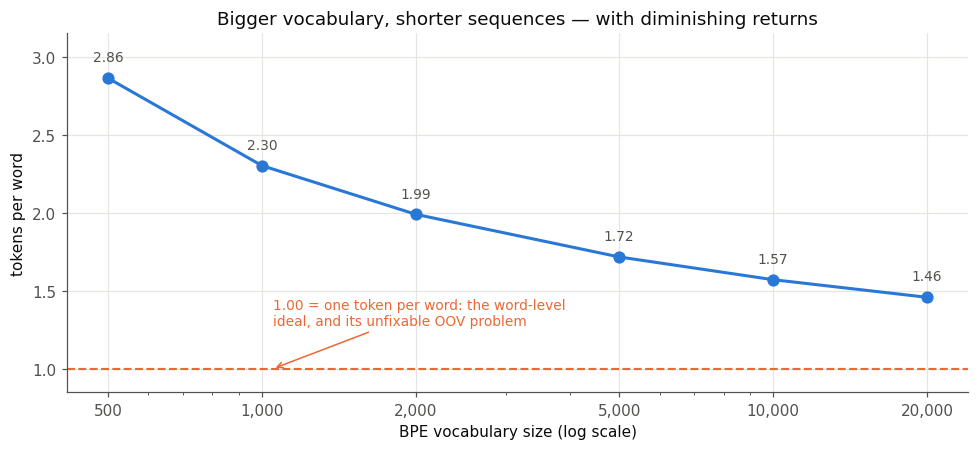

In [16]:
fig, ax = plt.subplots()
ax.plot(sizes, tokens_per_word, color=C1, lw=2, marker="o", ms=7)
for v, tpw in zip(sizes, tokens_per_word):
    ax.annotate(f"{tpw:.2f}", (v, tpw), textcoords="offset points", xytext=(0, 11),
                ha="center", fontsize=9, color=MUTED)
ax.axhline(1.0, color=C2, lw=1.4, ls="--")
ax.annotate("1.00 = one token per word: the word-level\nideal, and its unfixable OOV problem",
            xy=(1_050, 1.0), xytext=(1_050, 1.28), color=C2, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=C2, lw=1.0))
ax.set_xscale("log")
ax.set_xticks(sizes)
ax.set_xticklabels([f"{s:,}" for s in sizes])
ax.set_xlabel("BPE vocabulary size (log scale)")
ax.set_ylabel("tokens per word")
ax.set_ylim(0.85, 3.15)
ax.set_title("Bigger vocabulary, shorter sequences — with diminishing returns")
plt.tight_layout()
plt.show()

The curve is the design space. Going 500 → 5,000 buys a 40% reduction in
sequence length; 10,000 → 20,000 buys 7% for twice the embedding table. Real
models sit where the curve flattens, weighted by how much they care about
non-English text: GPT-2 chose 50,257, `cl100k_base` 100,277, `o200k_base`
200,019 — and §5 shows exactly what that last jump bought.

Two costs pull in opposite directions, which is why there is an optimum at all:

- **A bigger vocabulary** means shorter sequences (cheaper attention, more text
  per context window) but a larger embedding matrix and softmax.
- **A smaller vocabulary** means a tiny embedding table but longer sequences, and
  attention cost grows *faster* than linearly in sequence length.

### 3.5 Three algorithms, one corpus

BPE is one of three merge algorithms in wide use. Train all three on *Moby-Dick* at the same
vocabulary size and hand them the same input, and the differences become
concrete rather than a table in a slide.

- **BPE** merges the most *frequent* pair.
- **WordPiece** (BERT) merges the pair that most improves corpus *likelihood* —
  roughly, `count(ab) / (count(a) × count(b))`, which prefers pairs that occur
  together more than chance. It marks continuations with `##`, and it has a real
  `[UNK]` token that really does get used.
- **Unigram** (SentencePiece) goes the other way: start with a large candidate
  vocabulary and *prune* the pieces that cost the least likelihood. It marks
  word starts with `▁` (U+2581, not an underscore).

In [17]:
wp = Tokenizer(models.WordPiece(unk_token="[UNK]"))
wp.pre_tokenizer = pre_tokenizers.Whitespace()
wp.train_from_iterator(TRAIN_LINES, trainers.WordPieceTrainer(
    vocab_size=5_000, special_tokens=["[UNK]"], show_progress=False))

ug = Tokenizer(models.Unigram())
ug.pre_tokenizer = pre_tokenizers.Metaspace()
ug.decoder = decoders.Metaspace()
ug.train_from_iterator(TRAIN_LINES, trainers.UnigramTrainer(
    vocab_size=5_000, special_tokens=["<unk>"], unk_token="<unk>", show_progress=False))

PROBE = "The whale's unbelievability 🙂"
print(f"input: {PROBE!r}\n")
print("BPE (byte-level, 5k):", trained[5_000].encode(PROBE).tokens)
print("WordPiece      (5k):", wp.encode(PROBE).tokens)
print("Unigram        (5k):", ug.encode(PROBE).tokens)

input: "The whale's unbelievability 🙂"

BPE (byte-level, 5k): ['ĠThe', 'Ġwhale', "'s", 'Ġunb', 'el', 'ie', 'v', 'ab', 'ility', 'Ġ', 'ð', 'Ł', 'Ļ', 'Ĥ']
WordPiece      (5k): ['The', 'whale', "'", 's', 'unb', '##el', '##ie', '##v', '##ability', '[UNK]']
Unigram        (5k): ['▁The', "▁whale's", '▁un', 'b', 'el', 'i', 'e', 'va', 'b', 'ility', '▁', '🙂']


### 3.6 `[UNK]` is not a historical curiosity

Look at the WordPiece line above. The emoji became **`[UNK]`** — the information
is gone, unrecoverably, before the model sees a single number. The byte-level BPE
line has no `[UNK]`, and it *cannot* have one.

This is not a toy artefact of our 5,000-piece model. It happens in
`bert-base-uncased`, a model still in production use everywhere.

> The next cell downloads two tokenizer files (a few hundred KB) from the Hugging
> Face Hub and caches them under `~/.cache/huggingface`. If you see a notice about
> *unauthenticated requests*, it is informational — anonymous downloads are fine
> at this volume, and nothing in this course requires a Hub account.

In [18]:
from transformers import AutoTokenizer

bert = AutoTokenizer.from_pretrained("bert-base-uncased")
gpt2 = AutoTokenizer.from_pretrained("gpt2")

PROBES = ["still upset 😤", "café", "東京の配送センター", "SKU-YZ68-8980", "🙏"]
print(f"{'input':<24} {'bert-base-uncased (WordPiece)':<46} gpt2 (byte-level BPE)")
print("-" * 118)
for p in PROBES:
    b, g = bert.tokenize(p), gpt2.tokenize(p)
    flag = "  <-- [UNK]" if "[UNK]" in b else ""
    print(f"{p:<24} {str(b):<46} {g}{flag}")

input                    bert-base-uncased (WordPiece)                  gpt2 (byte-level BPE)
----------------------------------------------------------------------------------------------------------------------
still upset 😤            ['still', 'upset', '[UNK]']                    ['still', 'Ġupset', 'ĠðŁĺ', '¤']  <-- [UNK]
café                     ['cafe']                                       ['c', 'af', 'Ã©']
東京の配送センター                ['東', '京', 'の', '[UNK]', '[UNK]', 'セ', '##ン', '##タ', '##ー'] ['æĿ', '±', 'äº', '¬', 'ãģ®é', 'ħ', 'į', 'éĢ', 'ģ', 'ãĤ»', 'ãĥ³', 'ãĤ¿', 'ãĥ¼']  <-- [UNK]
SKU-YZ68-8980            ['sk', '##u', '-', 'y', '##z', '##6', '##8', '-', '89', '##80'] ['SK', 'U', '-', 'Y', 'Z', '68', '-', '89', '80']
🙏                        ['[UNK]']                                      ['ðŁ', 'Ļ', 'ı']  <-- [UNK]


Four things in that table, and all four matter:

1. **`bert-base-uncased` destroys the emoji.** `😤` → `[UNK]`, `🙏` → `[UNK]`.
   Every emoji in your support corpus maps to the *same* symbol, so "customer is
   furious" and "customer is grateful" become the identical feature. On a
   support-ticket corpus that is not a rounding error.
2. **It also destroys the accent**: `café` → the single token `cafe`. That is not
   the vocabulary, it is the tokenizer's *normalizer* running `strip_accents`
   before anything else. `café`/`cafe`/`Café` collapse into one token — helpful
   for search, fatal if you needed to reproduce the input.
3. **Two of the nine Japanese characters are also `[UNK]`.** BERT's vocabulary
   contains *some* CJK characters, so the damage is partial and therefore harder
   to notice than a total failure would be.
4. **GPT-2 emits no `[UNK]` and structurally cannot.** Look at what it produced
   for the emoji: `['ĠðŁĺ', '¤']`. Those are not corrupted characters — they are
   the individual *bytes* of the UTF-8 encoding, rendered in a printable
   alphabet so the vocabulary file stays readable text.

### 3.7 Byte-level BPE: why `[UNK]` becomes impossible

The trick behind byte-level BPE: run BPE over the 256 possible **bytes** instead
of over characters. Every possible input is a byte string, the 256 bytes are all
in the vocabulary by construction, so every possible input is representable.
`Ġ` marks a leading space and the odd-looking glyphs are bytes 128–255 mapped to
printable code points so the vocabulary file stays text.

In [19]:
s = "😤"
print(f"{s!r} as UTF-8 bytes: {list(s.encode('utf-8'))}")
print(f"gpt2 tokens         : {gpt2.tokenize(s)}")
print(f"gpt2 ids            : {gpt2(s)['input_ids']}")
print(f"round-trip          : {gpt2.decode(gpt2(s)['input_ids'])!r}  "
      f"-> lossless: {gpt2.decode(gpt2(s)['input_ids']) == s}\n")

print("The space marker Ġ, which is why leading spaces matter:")
for variant in ["refund", " refund", "Refund", " Refund"]:
    print(f"  {variant!r:<12} -> {gpt2.tokenize(variant)}")

'😤' as UTF-8 bytes: [240, 159, 152, 164]
gpt2 tokens         : ['ðŁĺ', '¤']
gpt2 ids            : [47249, 97]
round-trip          : '😤'  -> lossless: True

The space marker Ġ, which is why leading spaces matter:
  'refund'     -> ['ref', 'und']
  ' refund'    -> ['Ġrefund']
  'Refund'     -> ['Ref', 'und']
  ' Refund'    -> ['ĠRef', 'und']


`"refund"` and `" refund"` are **different tokens with different IDs**. This is
the single most common source of confusion when people hand-build prompts and
few-shot examples — a stray leading space silently changes the token sequence.

### 3.8 SentencePiece: a framework, not an algorithm

SentencePiece is frequently mislabelled "a tokenization algorithm". It is not —
it is a *framework* that can run BPE **or** Unigram, and its actual contributions
are two design decisions:

1. **It treats the input as a raw character stream**, spaces included. There is
   no language-specific pre-tokenization step, so it works on Japanese and
   Chinese without a word segmenter. The space becomes `▁`, an ordinary symbol.
2. **Round-tripping is lossless by construction** — `decode(encode(x)) == x`,
   exactly, because the space was never thrown away in the first place.

With `byte_fallback=True` it also gets the byte-level guarantee: anything it has
no piece for decomposes into `<0x..>` byte tokens rather than `<unk>`.

In [20]:
import io

import sentencepiece as spm

model_buf = io.BytesIO()
spm.SentencePieceTrainer.train(
    sentence_iterator=iter(TRAIN_LINES), model_writer=model_buf,
    vocab_size=4_000, model_type="unigram", character_coverage=0.9995,
    byte_fallback=True, minloglevel=2,
)
sp = spm.SentencePieceProcessor(model_proto=model_buf.getvalue())

probe = "The whale's blubber — 🙂 café 東京"
pieces = sp.encode(probe, out_type=str)
print("pieces:", pieces, "\n")
print(f"decoded : {sp.decode(sp.encode(probe))!r}")
print(f"lossless: {sp.decode(sp.encode(probe)) == probe}")

pieces: ['▁The', '▁whale', "'", 's', '▁blubber', '▁', '<0xE2>', '<0x80>', '<0x94>', '▁', '<0xF0>', '<0x9F>', '<0x99>', '<0x82>', '▁ca', 'f', '<0xC3>', '<0xA9>', '▁', '<0xE6>', '<0x9D>', '<0xB1>', '<0xE4>', '<0xBA>', '<0xAC>'] 

decoded : "The whale's blubber — 🙂 café 東京"
lossless: True


Every `<0x..>` in that output is a raw byte the model had no learned piece for —
the em dash, the emoji, the accented `é`, and both Japanese characters. It
still decodes back to the exact original string. Compare with `bert-base-uncased`,
which silently returned `cafe`.

**The four-family summary**, now that you have seen each one run:

| | Merge rule | Space marker | `[UNK]` possible? | Used by |
|---|---|---|---|---|
| BPE | most frequent pair | (none / `</w>`) | yes | early NMT systems |
| WordPiece | best likelihood gain | `##` on continuations | **yes, and it fires** | BERT, DistilBERT |
| Unigram | prune lowest-loss pieces | `▁` on word starts | yes (rare) | T5, ALBERT, XLNet |
| **Byte-level BPE** | most frequent **byte** pair | `Ġ` on leading space | **no — impossible** | GPT-2/3/4, Llama, most modern LLMs |

---

## 4. Living with a tokenizer

The algorithm is the interesting half. This is the half that breaks your code.

### 4.1 Special tokens

A tokenizer adds symbols that were never in your text. BERT wraps every sequence
in `[CLS]` … `[SEP]`; GPT-2 has `<|endoftext|>` as a document separator. They
occupy positions, they cost context, and forgetting them is why your sequence
lengths do not add up.

In [21]:
print("bert special tokens:", bert.all_special_tokens)
print("gpt2 special tokens:", gpt2.all_special_tokens, "\n")

s = "The refund was never issued."
enc = bert(s)
print("bert tokens:", bert.convert_ids_to_tokens(enc["input_ids"]))
print(f"  {len(s.split())} words in -> {len(enc['input_ids'])} ids out "
      f"(2 of them are special)\n")
print("gpt2 tokens:", gpt2.tokenize(s))
print(f"  gpt2 adds nothing by default — {len(gpt2(s)['input_ids'])} ids")

bert special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']
gpt2 special tokens: ['<|endoftext|>'] 

bert tokens: ['[CLS]', 'the', 'ref', '##und', 'was', 'never', 'issued', '.', '[SEP]']
  5 words in -> 9 ids out (2 of them are special)

gpt2 tokens: ['The', 'Ġrefund', 'Ġwas', 'Ġnever', 'Ġissued', '.']
  gpt2 adds nothing by default — 6 ids


### 4.2 Padding, truncation, and `attention_mask`

Models want rectangular tensors; sentences are ragged. Padding squares them off,
and the `attention_mask` is what tells the model which positions are real. Get
this wrong and the model happily attends to your padding and learns from it.

In [22]:
batch_texts = [
    "Refund please.",
    "Tracking 1Z9847 says delivered but nothing arrived and I need this resolved today.",
    "Where is my order?",
]
batch = bert(batch_texts, padding=True, truncation=True, max_length=12,
             return_tensors="pt")
batch = {k: v.to(device) for k, v in batch.items()}

print("tensor shapes:", {k: tuple(v.shape) for k, v in batch.items()})
print("on device    :", batch["input_ids"].device, "\n")
for i, text in enumerate(batch_texts):
    toks = bert.convert_ids_to_tokens(batch["input_ids"][i])
    mask = batch["attention_mask"][i].tolist()
    print(f"[{i}] {text[:42]!r}")
    print(f"     tokens: {toks}")
    print(f"     mask  : {mask}   ({sum(mask)} real, {len(mask) - sum(mask)} padding)")

tensor shapes: {'input_ids': (3, 12), 'token_type_ids': (3, 12), 'attention_mask': (3, 12)}
on device    : mps:0 

[0] 'Refund please.'
     tokens: ['[CLS]', 'ref', '##und', 'please', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
     mask  : [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]   (6 real, 6 padding)
[1] 'Tracking 1Z9847 says delivered but nothing'
     tokens: ['[CLS]', 'tracking', '1', '##z', '##9', '##8', '##47', 'says', 'delivered', 'but', 'nothing', '[SEP]']
     mask  : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]   (12 real, 0 padding)
[2] 'Where is my order?'
     tokens: ['[CLS]', 'where', 'is', 'my', 'order', '?', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
     mask  : [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]   (7 real, 5 padding)


Two things to notice. Sequence 1 hit `max_length=12` and was **truncated** — the
words after position 12 are simply gone, and `[SEP]` was moved to the end so the
model still sees a well-formed sequence. Sequences 0 and 2 were **padded**, and
their masks are 0 in exactly the padded positions.

`truncation=True` is a silent data-loss switch. It is also the correct default,
because the alternative is a crash. Know which of your documents it is eating.

### 4.3 `offset_mapping`: getting back to the original characters

Tokenization is destructive by default — once you have IDs you have lost the
character positions. Fast tokenizers can hand you an offset per token: the
`(start, end)` character span it came from. This is what makes it possible to
highlight a model's answer in the source document.

In [23]:
claim = "Order ORD-2026-448120 was refunded on 2026-08-14."
enc = bert(claim, return_offsets_mapping=True)
toks = bert.convert_ids_to_tokens(enc["input_ids"])

print(f"{'token':<14} {'span':>10}  slice of the original string")
for tok, (a, b) in zip(toks, enc["offset_mapping"]):
    print(f"{tok:<14} {f'({a},{b})':>10}  {claim[a:b]!r}")

token                span  slice of the original string
[CLS]               (0,0)  ''
order               (0,5)  'Order'
or                  (6,8)  'OR'
##d                 (8,9)  'D'
-                  (9,10)  '-'
202               (10,13)  '202'
##6               (13,14)  '6'
-                 (14,15)  '-'
44                (15,17)  '44'
##8               (17,18)  '8'
##12              (18,20)  '12'
##0               (20,21)  '0'
was               (22,25)  'was'
ref               (26,29)  'ref'
##und             (29,32)  'und'
##ed              (32,34)  'ed'
on                (35,37)  'on'
202               (38,41)  '202'
##6               (41,42)  '6'
-                 (42,43)  '-'
08                (43,45)  '08'
-                 (45,46)  '-'
14                (46,48)  '14'
.                 (48,49)  '.'
[SEP]               (0,0)  ''


In [24]:
# Given a character span, which tokens cover it?
start, end = claim.index("ORD-2026-448120"), claim.index("ORD-2026-448120") + 15
covering = [i for i, (a, b) in enumerate(enc["offset_mapping"])
            if a != b and a < end and b > start]
print(f"characters [{start}:{end}] = {claim[start:end]!r}")
print(f"covered by token indices {covering} -> {[toks[i] for i in covering]}")

characters [6:21] = 'ORD-2026-448120'
covered by token indices [2, 3, 4, 5, 6, 7, 8, 9, 10, 11] -> ['or', '##d', '-', '202', '##6', '-', '44', '##8', '##12', '##0']


Notice `(0, 0)` on `[CLS]` and `[SEP]` — special tokens map to an empty span,
which is how you filter them out. The order ID alone consumed **ten** tokens, and
that alignment is exactly what an extractive QA or NER system uses to point back
at the source text. It is also why `offset_mapping` is only available on *fast*
tokenizers: the slow Python implementations do not track it.

### 4.4 The tokenizer and the model are one artefact

Token ID 464 means "The" to GPT-2 and something else entirely to BERT. IDs are
indices into a specific vocabulary file. Mixing them does not raise an
exception — it produces confident nonsense, which is much worse.

In [25]:
s = "The refund for order ORD-2026-448120 was never issued."
ids = gpt2(s)["input_ids"]
print(f"encoded with gpt2  ({gpt2.vocab_size:,} vocab): {ids[:12]} ...")
print(f"decoded with gpt2  : {gpt2.decode(ids)!r}")
print(f"decoded with bert  ({bert.vocab_size:,} vocab): {bert.decode(ids[:12])!r}")

encoded with gpt2  (50,257 vocab): [464, 12929, 329, 1502, 6375, 35, 12, 1238, 2075, 12, 31115, 10232] ...
decoded with gpt2  : 'The refund for order ORD-2026-448120 was never issued.'
decoded with bert  (30,522 vocab): '[unused459] preparations [unused324] ᵐ uniform [unused34] [unused11] ւing [unused11] crucial'


No error. No warning. Just garbage that looks like text. **Always load the
tokenizer with `from_pretrained` using the same identifier as the model**, and
never cache token IDs across a model change.

### 4.5 Training a tokenizer on *your* corpus

`from_pretrained` is right 95% of the time. The other 5%: a domain whose
vocabulary the general tokenizer has never seen — clinical notes, legal
citations, chemical names, log lines, or the SKUs and order IDs in our support
inbox. Here is what domain training actually buys, measured.

In [26]:
ticket_texts = [t["text"] for t in TICKETS]

domain = Tokenizer(models.BPE())
domain.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
domain.decoder = decoders.ByteLevel()
domain.train_from_iterator(ticket_texts, trainers.BpeTrainer(
    vocab_size=5_000, special_tokens=["<|endoftext|>"], show_progress=False,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()))

n_domain = sum(len(domain.encode(t).ids) for t in ticket_texts)
n_gpt2 = sum(len(gpt2(t)["input_ids"]) for t in ticket_texts)
n_moby = sum(len(trained[5_000].encode(t).ids) for t in ticket_texts)

print(f"{'tokenizer':<32} {'vocab':>8} {'tokens for all 400 tickets':>28}")
print(f"{'gpt2 (general web text)':<32} {gpt2.vocab_size:>8,} {n_gpt2:>28,}")
print(f"{'BPE trained on Moby-Dick':<32} {5_000:>8,} {n_moby:>28,}")
print(f"{'BPE trained on the tickets':<32} {5_000:>8,} {n_domain:>28,}")
print(f"\nin-domain vs gpt2:      {100 * (1 - n_domain / n_gpt2):.1f}% FEWER tokens, "
      f"on 1/10th the vocabulary")
print(f"wrong-domain vs gpt2:   {100 * (n_moby / n_gpt2 - 1):.1f}% MORE tokens")

tokenizer                           vocab   tokens for all 400 tickets
gpt2 (general web text)            50,257                       17,461
BPE trained on Moby-Dick            5,000                       26,897
BPE trained on the tickets          5,000                       14,686

in-domain vs gpt2:      15.9% FEWER tokens, on 1/10th the vocabulary
wrong-domain vs gpt2:   54.0% MORE tokens


In [27]:
probe = "Refund for ORD-2026-448120, SKU-YZ68-8980, tracking 1Z485761809742."
print("gpt2         :", gpt2.tokenize(probe))
print()
print("domain BPE 5k:", domain.encode(probe).tokens)

gpt2         : ['Ref', 'und', 'Ġfor', 'ĠOR', 'D', '-', '20', '26', '-', '448', '120', ',', 'ĠSK', 'U', '-', 'Y', 'Z', '68', '-', '89', '80', ',', 'Ġtracking', 'Ġ1', 'Z', '48', '576', '18', '09', '7', '42', '.']

domain BPE 5k: ['ĠRefund', 'Ġfor', 'ĠORD', '-', '2026', '-', '448', '1', '20', ',', 'ĠSKU', '-', 'YZ', '68', '-', '8980', ',', 'Ġtracking', 'Ġ1', 'Z', '485761809742', '.']


Two results in that table, and the second one is the more useful lesson.

**In-domain training wins.** The ticket-trained tokenizer learned `ORD`, `2026`,
`SKU`, `8980` and the whole tracking number `485761809742` as single units,
because in *this* corpus they are frequent. GPT-2 shreds them into 32 tokens
against the domain model's 22 — because in general web text those strings are not
frequent at all.

**Wrong-domain training loses badly.** The identically-sized tokenizer trained on
*Moby-Dick* needs **54% more** tokens than GPT-2 on the same tickets. A tokenizer
is not "better" or "worse" in the abstract; it is fitted to a distribution, and
using it off-distribution costs you real money. This is the same fitting logic
you already know from ISM 6251, applied one layer earlier than usual.

Now the caveat, before anyone goes and trains one: **a custom tokenizer means you
can no longer use anyone's pretrained model.** Every embedding in every public
checkpoint is indexed by *its* vocabulary. Training a tokenizer commits you to
training a model. That is why the answer is "use `from_pretrained`" almost every
time, and why the exceptions are organisations pretraining from scratch anyway.

---

## 5. Tokens as money, and as failure

Tokens are the unit of billing, the unit of the context window, and the unit of
several famous model failures. This section is the one your future employer
cares about.

### 5.1 The same document costs different amounts in different languages

Five translations of the *identical document* — the Universal Declaration of
Human Rights. Same meaning, same content, five scripts. Any difference in token
count is a property of the *tokenizer*, not of the text.

In [28]:
import tiktoken

cl100k = tiktoken.get_encoding("cl100k_base")   # GPT-3.5/4-era
o200k = tiktoken.get_encoding("o200k_base")     # GPT-4o-era

rows = []
for name, rec in UDHR.items():
    text = rec["text"]
    rows.append({
        "language": name, "script": rec["script"],
        "chars": len(text), "words": len(text.split()),
        "cl100k": len(cl100k.encode(text)), "o200k": len(o200k.encode(text)),
    })

base = next(r for r in rows if r["language"] == "English")
print(f"{'language':<22} {'script':<18} {'chars':>7} {'cl100k':>8} {'o200k':>8} "
      f"{'cl100k vs EN':>13} {'o200k vs EN':>12}")
print("-" * 96)
for r in rows:
    print(f"{r['language']:<22} {r['script']:<18} {r['chars']:>7,} {r['cl100k']:>8,} "
          f"{r['o200k']:>8,} {r['cl100k'] / base['cl100k']:>12.2f}× "
          f"{r['o200k'] / base['o200k']:>11.2f}×")

language               script               chars   cl100k    o200k  cl100k vs EN  o200k vs EN
------------------------------------------------------------------------------------------------
English                Latin               10,637    2,016    2,017         1.00×        1.00×
German                 Latin               11,936    3,295    2,551         1.63×        1.26×
Spanish                Latin               11,964    2,989    2,474         1.48×        1.23×
Hindi                  Devanagari          11,463   11,228    3,368         5.57×        1.67×
Chinese (Simplified)   Han (Simplified)     2,988    3,451    2,367         1.71×        1.17×


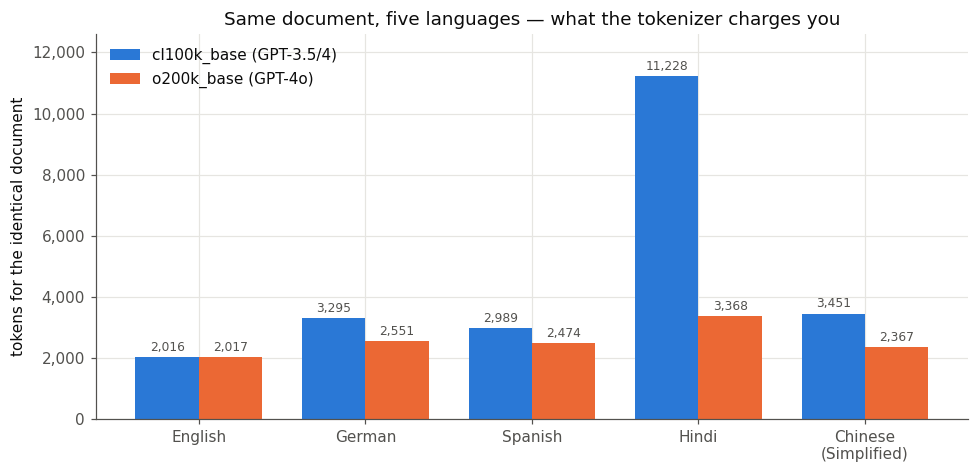

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.4))
labels = [r["language"].replace(" (Simplified)", "\n(Simplified)") for r in rows]
x = np.arange(len(rows))
w = 0.38
b1 = ax.bar(x - w / 2, [r["cl100k"] for r in rows], w, color=C1, label="cl100k_base (GPT-3.5/4)")
b2 = ax.bar(x + w / 2, [r["o200k"] for r in rows], w, color=C2, label="o200k_base (GPT-4o)")
ax.bar_label(b1, labels=[f"{r['cl100k']:,}" for r in rows], padding=2, fontsize=8, color=MUTED)
ax.bar_label(b2, labels=[f"{r['o200k']:,}" for r in rows], padding=2, fontsize=8, color=MUTED)
ax.set_xticks(x, labels)
ax.set_ylabel("tokens for the identical document")
ax.set_ylim(0, 12_600)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_title("Same document, five languages — what the tokenizer charges you")
ax.legend(loc="upper left")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

This is the fairness result, and it is not a rounding error. Under `cl100k_base`
a Hindi speaker pays **5.57× more** than an English speaker for the identical
document, waits proportionally longer for it, and hits the context-window ceiling
5.57× sooner. The model is not *worse* at Hindi in this measurement — it is more
*expensive* at Hindi, which is a subtler and more insidious problem, because
nothing on the invoice line marked "tokens" tells you it is happening.

`o200k_base` was designed partly to fix this, and it measurably does: Hindi falls
from **11,228 tokens to 3,368**, a 3.3× improvement, and the gap against English
narrows from 5.57× to **1.67×**. Narrows — it does not close, and no vocabulary
of any size makes it close entirely.

Two footnotes on the table. Chinese needs only ~3,000 *characters* for the whole
document because the script is dense, yet still costs more tokens than English's
10,637 characters. And the `words` column is meaningless for Chinese — there are
no whitespace word boundaries to count — which is exactly why the comparison is
reported per document and per character rather than per word.

### 5.2 Pricing a real corpus

Now the business question: what does it cost to send our support archive to a
frontier model?

In [30]:
# List prices per 1M tokens, USD. VERIFY THESE against the vendor pricing page
# before quoting them anywhere — they change, and they only move down.
# Checked: August 2026.
PRICES = {
    "gpt-4o-mini":       {"in": 0.15, "out": 0.60,  "encoding": "o200k_base"},
    "gpt-4o":            {"in": 2.50, "out": 10.00, "encoding": "o200k_base"},
    "claude-sonnet":     {"in": 3.00, "out": 15.00, "encoding": "o200k_base"},
}

corpus = "\n\n".join(t["text"] for t in TICKETS)
n_in = len(o200k.encode(corpus))
n_out = 60 * len(TICKETS)      # assume a ~60-token structured summary per ticket

print(f"corpus: {len(TICKETS)} tickets, {len(corpus):,} characters, {n_in:,} input tokens")
print(f"assumed output: {n_out:,} tokens ({n_out // len(TICKETS)}/ticket)\n")
print(f"{'model':<16} {'input $':>9} {'output $':>9} {'total $':>9}  "
      f"{'$ / 1M tickets':>15} {'$ / year at 1M/mo':>18}")
print("-" * 92)
for model, p in PRICES.items():
    ci = n_in / 1e6 * p["in"]
    co = n_out / 1e6 * p["out"]
    per_million = (ci + co) * (1_000_000 / len(TICKETS))
    print(f"{model:<16} {ci:>9.4f} {co:>9.4f} {ci + co:>9.4f}  "
          f"{per_million:>15,.0f} {per_million * 12:>18,.0f}")

corpus: 400 tickets, 58,862 characters, 15,860 input tokens
assumed output: 24,000 tokens (60/ticket)

model              input $  output $   total $   $ / 1M tickets  $ / year at 1M/mo
--------------------------------------------------------------------------------------------
gpt-4o-mini         0.0024    0.0144    0.0168               42                503
gpt-4o              0.0396    0.2400    0.2797              699              8,390
claude-sonnet       0.0476    0.3600    0.4076            1,019             12,227


Four hundred tickets costs less than a coffee. **That is the trap.** Scale it to
a million tickets a month — an ordinary mid-size retailer — and the same
workload runs from roughly $500/year to $12,000/year depending on nothing but
which model string somebody typed into a config file. A 24× spread, chosen by
default.

Note where the money actually goes: output is 24,000 of the 39,860 tokens but
**86% of the bill**, because output tokens are priced 4–5× input tokens on every
provider. "Make the summaries shorter" is very often a bigger lever than "make
the prompt shorter", and it is the one people forget to pull.

Costing a pipeline in tokens *before* you build it is a ten-minute exercise that
has killed a lot of bad architectures very cheaply.

### 5.3 Tokens are also the context window

In [31]:
CONTEXTS = {"8k (GPT-3.5 era)": 8_192, "128k (GPT-4o)": 128_000, "200k (Claude)": 200_000}
print(f"the whole support archive = {n_in:,} tokens\n")
print(f"{'context window':<20} {'copies of the archive that fit':>32}")
for name, size in CONTEXTS.items():
    print(f"{name:<20} {size / n_in:>32.1f}")

moby_tokens = len(o200k.encode(MOBY))
print(f"\nMoby-Dick alone = {moby_tokens:,} tokens "
      f"({moby_tokens / 128_000:.1f}× a 128k context window)")

the whole support archive = 15,860 tokens

context window         copies of the archive that fit
8k (GPT-3.5 era)                                  0.5
128k (GPT-4o)                                     8.1
200k (Claude)                                    12.6



Moby-Dick alone = 308,885 tokens (2.4× a 128k context window)


"Just put everything in the context window" stops being a plan at surprisingly
small scale — and cost grows with what you put in there, every single call.
Managing what actually goes into that budget is its own engineering discipline
later in this course.

### 5.4 Why the model cannot count the r's in *strawberry*

This is the most-quoted "LLMs are dumb" example on the internet, and it is
really a tokenization result. The model never sees the letters.

In [32]:
for enc_name, enc in [("cl100k_base", cl100k), ("o200k_base", o200k)]:
    for text in ["strawberry", " strawberry"]:
        ids = enc.encode(text)
        print(f"{enc_name:<12} {text!r:<14} {[enc.decode([i]) for i in ids]}  "
              f"({len(ids)} token{'s' if len(ids) != 1 else ''})")

cl100k_base  'strawberry'   ['str', 'aw', 'berry']  (3 tokens)
cl100k_base  ' strawberry'  [' strawberry']  (1 token)
o200k_base   'strawberry'   ['st', 'raw', 'berry']  (3 tokens)
o200k_base   ' strawberry'  [' strawberry']  (1 token)


In context — where it is preceded by a space — **`" strawberry"` is a single
token** under both encodings. The model is being asked to count letters in
something it perceives as one indivisible symbol. That is not a reasoning
failure; it is an information-availability failure. Asking it to spell the word
out first (`s-t-r-a-w-b-e-r-r-y`) forces separate tokens and usually fixes it,
which is a good diagnostic for whether a failure is reasoning or representation.

### 5.5 The same fault, in arithmetic

In [33]:
print(f"{'number':<12} {'cl100k_base pieces':<28} o200k_base pieces")
for n in ["7", "42", "127", "1234", "12345", "9999999", "3.14159"]:
    a = [cl100k.decode([i]) for i in cl100k.encode(n)]
    b = [o200k.decode([i]) for i in o200k.encode(n)]
    print(f"{n:<12} {str(a):<28} {b}")

number       cl100k_base pieces           o200k_base pieces
7            ['7']                        ['7']
42           ['42']                       ['42']
127          ['127']                      ['127']
1234         ['123', '4']                 ['123', '4']
12345        ['123', '45']                ['123', '45']
9999999      ['999', '999', '9']          ['999', '999', '9']
3.14159      ['3', '.', '141', '59']      ['3', '.', '141', '59']


`1234` is `123` + `4`. `12345` is `123` + `45`. The digits do not line up in
place-value columns, so column-wise arithmetic — the algorithm you learned in
primary school — is not available to the model in any natural form. Some
tokenizers now force digits into fixed 1- or 3-digit groups precisely because of
this. **The engineering answer remains: give the model a calculator tool** rather
than hoping it internalises base-10.

### 5.6 Unicode normalization and the `café` trap

In [34]:
composed   = "caf\u00e9"        # é as ONE code point (U+00E9)  -- NFC
decomposed = "cafe\u0301"       # e + combining acute (U+0065 U+0301) -- NFD

print(f"visually:  {composed!r}  vs  {decomposed!r}")
print(f"equal?     {composed == decomposed}")
print(f"len:       {len(composed)} vs {len(decomposed)}")
print(f"utf-8:     {composed.encode()} vs {decomposed.encode()}\n")

for label, s in [("composed (NFC)", composed), ("decomposed (NFD)", decomposed)]:
    ids = cl100k.encode(s)
    print(f"{label:<18} {len(ids)} tokens {[cl100k.decode([i]) for i in ids]}")

print(f"\nafter NFC normalization, equal? "
      f"{unicodedata.normalize('NFC', composed) == unicodedata.normalize('NFC', decomposed)}")

visually:  'café'  vs  'café'
equal?     False
len:       4 vs 5
utf-8:     b'caf\xc3\xa9' vs b'cafe\xcc\x81'

composed (NFC)     2 tokens ['ca', 'fé']
decomposed (NFD)   3 tokens ['ca', 'fe', '́']

after NFC normalization, equal? True


Two strings that render identically on screen, compare unequal, hash differently,
and tokenize to different sequences. Text arriving from macOS filesystems, from
some web forms, and from PDF extraction is routinely decomposed. **`NFC` first,
then everything else** is the rule; a deduplication step that skips it will report
duplicates as distinct forever.

`NFKC` goes further — it folds *compatibility* characters, which is either
exactly what you want or a silent data corruption, depending on the task:

In [35]:
for s in ["ﬁle", "①②③", "ｆｕｌｌｗｉｄｔｈ", "x²", "①"]:
    print(f"{s!r:<18} NFC-> {unicodedata.normalize('NFC', s)!r:<18} "
          f"NFKC-> {unicodedata.normalize('NFKC', s)!r}")

'ﬁle'              NFC-> 'ﬁle'              NFKC-> 'file'
'①②③'              NFC-> '①②③'              NFKC-> '123'
'ｆｕｌｌｗｉｄｔｈ'        NFC-> 'ｆｕｌｌｗｉｄｔｈ'        NFKC-> 'fullwidth'
'x²'               NFC-> 'x²'               NFKC-> 'x2'
'①'                NFC-> '①'                NFKC-> '1'


NFKC turned `x²` into `x2`. For a search index that is a win. For a chemistry or
maths corpus it just destroyed the meaning. Normalization is never free; it is a
choice about what you are willing to treat as the same thing.

### 5.7 Checking your local count against the bill *(needs an API key)*

`tiktoken` is exact for the OpenAI encodings — but only for the message *content*.
The API also charges for the chat-template scaffolding around your messages, so a
naive local count under-reports. The cell below verifies this against the real
`usage` field. It is guarded, and it is skipped in the published run; the cached
output is shown underneath so you can see what it produces.

In [36]:
prompt = "Summarise this support ticket in one sentence:\n\n" + TICKETS[0]["text"]
local_estimate = len(o200k.encode(prompt))
print(f"local tiktoken estimate for the message content: {local_estimate} tokens")

if os.getenv("OPENAI_API_KEY"):
    from openai import OpenAI

    client = OpenAI()
    resp = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": prompt}],
        max_tokens=60,
    )
    print(f"API-reported prompt_tokens: {resp.usage.prompt_tokens}")
    print(f"overhead from the chat template: "
          f"{resp.usage.prompt_tokens - local_estimate} tokens")
    print(f"completion_tokens: {resp.usage.completion_tokens}")
    print("\nresponse:", resp.choices[0].message.content)
else:
    print("OPENAI_API_KEY not set — skipping the live call. Cached output below.")

local tiktoken estimate for the message content: 55 tokens
OPENAI_API_KEY not set — skipping the live call. Cached output below.


**Cached output from a run with a key set** (2026-08-17, `gpt-4o-mini`):

```
local tiktoken estimate for the message content: 55 tokens
API-reported prompt_tokens: 62
overhead from the chat template: 7 tokens
completion_tokens: 34

response: The customer reports that tracking number 1Z485761809742 shows their
Quarry ceramic mug set as delivered, but nothing arrived, and they need the gift
by 2026-04-09.
```

Seven tokens of overhead on a 55-token message — **13%** — because the provider
wraps every message in role markers and primes the reply. Per call it is small.
Per *conversation* it is not: the scaffolding is charged once per message, so a
20-turn chat carries it twenty times, on top of resending the whole history each
turn.

The working rule: **estimate locally with `tiktoken` to plan, reconcile against
`usage` to budget.** Never quote a projected API bill from a local count alone.

---

## 6. Normalization, briefly

Case folding, stopword removal, stemming and lemmatization were the standard
opening moves of every NLP pipeline for thirty years. Then they largely stopped.
Understanding *why* is more useful than memorising the techniques, so let us
measure what they do and then ask what they cost.

### 6.1 What they buy: a smaller vocabulary

In [37]:
from nltk.corpus import stopwords as nltk_stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

for pkg in ("stopwords", "wordnet"):
    nltk.download(pkg, quiet=True)

raw_tokens = re.findall(r"[A-Za-z']+", MOBY)
stops = set(nltk_stopwords.words("english"))
ps, wl = PorterStemmer(), WordNetLemmatizer()

lowered = [t.lower() for t in raw_tokens]
no_stops = [t for t in lowered if t not in stops]
stemmed = {ps.stem(t) for t in set(no_stops)}

print(f"NLTK English stopword list: {len(stops)} words "
      f"(version-dependent — check yours)\n")
print(f"{'stage':<34} {'types':>8} {'tokens':>10}")
print(f"{'raw':<34} {len(set(raw_tokens)):>8,} {len(raw_tokens):>10,}")
print(f"{'+ lowercased':<34} {len(set(lowered)):>8,} {len(lowered):>10,}")
print(f"{'+ stopwords removed':<34} {len(set(no_stops)):>8,} {len(no_stops):>10,}")
print(f"{'+ Porter stemmed':<34} {len(stemmed):>8,} {len(no_stops):>10,}")
print(f"\nnet: {100 * (1 - len(stemmed) / len(set(raw_tokens))):.0f}% fewer types, "
      f"{100 * (1 - len(no_stops) / len(raw_tokens)):.0f}% fewer tokens")

NLTK English stopword list: 198 words (version-dependent — check yours)



stage                                 types     tokens
raw                                  19,605    216,106
+ lowercased                         17,500    216,106
+ stopwords removed                  17,334    111,009
+ Porter stemmed                     11,069    111,009

net: 44% fewer types, 49% fewer tokens


Real savings: 44% fewer vocabulary entries, half the tokens. In 1998, with a
sparse term-document matrix that had to fit in memory, that was the difference
between a system that ran and one that did not.

### 6.2 What they cost: stemming vs lemmatization

In [38]:
probe_words = ["running", "runs", "ran", "better", "studies", "studying",
               "university", "universal", "was", "mice", "caring", "organization"]
print(f"{'word':<14} {'Porter stem':<14} {'lemma (verb)':<14} {'lemma (noun)':<14}")
print("-" * 60)
for w in probe_words:
    print(f"{w:<14} {ps.stem(w):<14} {wl.lemmatize(w, 'v'):<14} {wl.lemmatize(w, 'n'):<14}")

word           Porter stem    lemma (verb)   lemma (noun)  
------------------------------------------------------------


running        run            run            running       
runs           run            run            run           
ran            ran            run            ran           
better         better         better         better        
studies        studi          study          study         
studying       studi          study          studying      
university     univers        university     university    
universal      univers        universal      universal     
was            wa             be             wa            
mice           mice           mice           mouse         
caring         care           care           caring        
organization   organ          organization   organization  


Stemming is a fast, dumb suffix-chopper with two characteristic failures, both
visible above:

- **Over-stemming (a collision):** `university` and `universal` both become
  `univers`; `organization` becomes `organ`. Unrelated concepts merged into one
  feature, permanently and invisibly.
- **Under-stemming (a miss):** `ran` stays `ran` while `running` and `runs`
  become `run`. The same verb now occupies two separate features.
- **And output that is not a word at all:** `was` → `wa`, `studies` → `studi`.
  That is by design — a stem is a matching key, not a word — but it means you can
  never show stemmed text to a human.

Lemmatization uses a dictionary and does better — `ran` → `run`, `mice` → `mouse`,
`was` → `be` — but only if you tell it the part of speech. Look at the `running`
row: as a verb it lemmatizes to `run`, as a noun it stays `running`. Getting that
right needs a POS tagger, which needs its own model, which is slower than the
stemmer by an order of magnitude.

### 6.3 What they cost, more seriously: stopwords delete the meaning

In [39]:
pairs = [
    ("The product was not damaged.", "The product was damaged."),
    ("I do not want a refund.",      "I want a refund."),
    ("This is the best I have used.", "This is the worst I have used."),
]
for a, b in pairs:
    fa = [t for t in re.findall(r"[a-z']+", a.lower()) if t not in stops]
    fb = [t for t in re.findall(r"[a-z']+", b.lower()) if t not in stops]
    print(f"{a!r}\n  -> {fa}")
    print(f"{b!r}\n  -> {fb}")
    print(f"  identical after stopword removal? {fa == fb}\n")

print("negations present in the NLTK stopword list:",
      [w for w in ["no", "not", "nor", "don't", "never", "cannot"] if w in stops])

'The product was not damaged.'
  -> ['product', 'damaged']
'The product was damaged.'
  -> ['product', 'damaged']
  identical after stopword removal? True

'I do not want a refund.'
  -> ['want', 'refund']
'I want a refund.'
  -> ['want', 'refund']
  identical after stopword removal? True

'This is the best I have used.'
  -> ['best', 'used']
'This is the worst I have used.'
  -> ['worst', 'used']
  identical after stopword removal? False

negations present in the NLTK stopword list: ['no', 'not', 'nor', "don't"]


The first two pairs mean the **opposite** of each other and are **identical**
after stopword removal, because `not` is in the standard stopword list. Run that
on a refund-request classifier and you have built something that cannot tell a
complaint from a compliment.

### 6.4 So why did the LLM era stop?

Because subword tokenization already solves the problem these techniques were
invented for, without discarding anything:

In [40]:
family = ["refund", "refunds", "refunded", "refunding", "refundable", "nonrefundable"]
print(f"{'word':<16} {'gpt2 (byte-level BPE)':<38} bert (WordPiece)")
print("-" * 78)
for w in family:
    print(f"{w:<16} {str(gpt2.tokenize(w)):<38} {bert.tokenize(w)}")

word             gpt2 (byte-level BPE)                  bert (WordPiece)
------------------------------------------------------------------------------
refund           ['ref', 'und']                         ['ref', '##und']
refunds          ['ref', 'und', 's']                    ['ref', '##unds']
refunded         ['ref', 'und', 'ed']                   ['ref', '##und', '##ed']
refunding        ['ref', 'und', 'ing']                  ['ref', '##und', '##ing']
refundable       ['ref', 'und', 'able']                 ['ref', '##unda', '##ble']
nonrefundable    ['non', 'ref', 'und', 'able']          ['non', '##re', '##fu', '##nda', '##ble']


Every member of the family shares the leading `ref` + `und` pieces, and each
keeps its own suffix as a separate token. The model therefore sees the shared
stem *and* the inflection, and can learn what each contributes — **without
anything being deleted**. The Porter stemmer collapses five of those six words
into the single key `refund` — tense, plural and the `-able` suffix all thrown
away permanently, and unrecoverably.

Two honest caveats. First, this is not linguistics: BPE learned `ref`+`und`
from raw frequency, and the split does not line up with any morpheme boundary a
linguist would draw. It is *good enough* for the model to generalise, which is
all that was required. Second, frequent words are not split at all — `running`,
`runs` and `ran` are each a single GPT-2 token, so their relationship has to be
learned entirely from context. That is fine, because learning relationships from
context is precisely what these models are for.

Meanwhile a transformer has ample capacity to learn that `the` is usually
uninformative, so deleting it in advance buys nothing — and risks the `not`
disaster above.

**Where normalization still earns its keep** — and this is a short, specific list:

| Still do it | Why |
|---|---|
| Unicode `NFC` | Always. Not optional. It is correctness, not preprocessing. |
| Case folding for **lexical** search | An inverted index matching `Refund` to `refund` is doing its job. |
| Stopword removal for **keyword** search | Indexing `the` wastes space and matches everything. |
| Stemming for **lexical** retrieval | Recall matters more than precision when a human reads the results. |
| Whitespace and control-character cleanup | Always, and cheap. |

| Do **not** do it | Why |
|---|---|
| Before a transformer of any kind | The tokenizer has its own normalizer. Doing it twice corrupts. |
| On anything where negation matters | Sentiment, safety, compliance, medical. |
| On text you must reproduce exactly | Citations, quotations, legal, code. |

The one-line rule: **normalize for lexical matching; leave it alone for
learned models.**

---

## 7. Where this goes next

What you can now defend with numbers you generated yourself:

1. **Word-level tokenization has no fix.** A perfect vocabulary from the first
   half of a book still leaves 7.2% of the second half out of vocabulary (§1.3).
2. **"How many tokens?" is not a property of a string.** Four word tokenizers
   gave four different answers on one paragraph (§2).
3. **BPE fits on one screen**, and our from-scratch version reproduces the
   Hugging Face trainer's vocabulary exactly — tie-breaks included (§3.1–§3.2).
4. **`[UNK]` is real.** `bert-base-uncased` destroys emoji and accents;
   byte-level BPE structurally cannot (§3.6–3.7).
5. **The tokenizer is part of the model.** GPT-2 IDs decoded by BERT produce
   fluent nonsense, silently (§4.4).
6. **Tokens are money.** Hindi costs 5.57× English under `cl100k_base`, and a
   short API call carries ~13% chat-template overhead on top of what you
   counted locally (§5.1, §5.7).
7. **Famous failures are representation failures.** `" strawberry"` is one
   token; `1234` splits as `123` + `4` (§5.4–5.5).
8. **Normalization is mostly over**, except for `NFC` and lexical search (§6).

**Next week** we take the token stream this notebook produces and start
*counting* it — turning documents into vectors, and defining what "similar"
means precisely enough to compute.

**Before then:** the graded assignment for this week builds a full tokenization
report over a supplied corpus. The practice assignment has you hand-execute BPE
merges and check them against `tokenizers` — exactly the §3.1/§3.2 loop, which is
the single best-value hour you can spend on this material.